In [1]:
# Install the required libraries if needed
!pip install pandas numpy matplotlib seaborn requests -q

# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import requests
from io import BytesIO

sns.set_theme(style="whitegrid")

In [2]:
url = "https://data.opencity.in/dataset/e57cd149-fd78-4853-80b8-47d3d082845e/resource/db3f6c55-bc4e-4e12-be01-49448686596b/download/877f72ae-d064-4a98-94b6-78db558204f6.csv"

try:
    response = requests.get(url, timeout=30)
    response.raise_for_status()

    df = pd.read_csv(BytesIO(response.content))
    print("Dataset loaded successfully!")

except Exception as e:
    print("Automatic download failed:", e)
    print("Please upload the CSV file manually.")

Dataset loaded successfully!


In [3]:
print("First five rows:")
display(df.head())

First five rows:


,Date,Rain,Temp Max,Temp Min,Location,Rain.1,Temp Max.1,Temp Min.1,Location.1
0,01-01-1951,0,25.05999947,6.590000153,POINT (72.5 23.5),0.0,27.860001,10.54,POINT (72.5 22.5)
1,02-01-1951,0,25.90999985,7.510000229,POINT (72.5 23.5),0.0,28.760000,10.57,POINT (72.5 22.5)
2,03-01-1951,0,26.46999931,8.529999733,POINT (72.5 23.5),0.0,29.969999,12.05,POINT (72.5 22.5)
3,04-01-1951,0,26.80999947,8.840000153,POINT (72.5 23.5),0.0,29.530001,11.88,POINT (72.5 22.5)
4,05-01-1951,0,26.28000069,8.479999542,POINT (72.5 23.5),0.0,28.690001,10.57,POINT (72.5 22.5)


In [4]:
print("\nColumn names:")
print(df.columns.tolist())


Column names:
['Date', 'Rain', 'Temp Max', 'Temp Min', 'Location', 'Rain.1', 'Temp Max.1', 'Temp Min.1', 'Location.1']


In [5]:
print("\nNumber of rows and columns:", df.shape)


Number of rows and columns: (26806, 9)


In [6]:
print("\nDataset information:")
df.info()


Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 26806 entries, 0 to 26805
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Date        26806 non-null  object 
 1   Rain        26806 non-null  object 
 2   Temp Max    26806 non-null  object 
 3   Temp Min    26805 non-null  object 
 4   Location    841 non-null    object 
 5   Rain.1      25568 non-null  float64
 6   Temp Max.1  25568 non-null  float64
 7   Temp Min.1  25567 non-null  float64
 8   Location.1  840 non-null    object 
dtypes: float64(3), object(6)
memory usage: 1.8+ MB


In [7]:
display(df.describe(include="all"))

,Date,Rain,Temp Max,Temp Min,Location,Rain.1,Temp Max.1,Temp Min.1,Location.1
count,26806,26806,26806,26805,841,25568.000000,25568.000000,25567.000000,840
unique,26806,4032,4824,5011,2,NaN,NaN,NaN,1
top,22-06-2024,0,-----,-----,POINT (72.5 23.5),NaN,NaN,NaN,POINT (72.5 22.5)
freq,1,22025,58,59,840,NaN,NaN,NaN,840
mean,NaN,NaN,NaN,NaN,NaN,2.162450,34.033113,21.062069,NaN
std,NaN,NaN,NaN,NaN,NaN,9.542517,3.794741,5.017226,NaN
min,NaN,NaN,NaN,NaN,NaN,0.000000,21.250000,5.230000,NaN
25%,NaN,NaN,NaN,NaN,NaN,0.000000,31.230000,16.760000,NaN
50%,NaN,NaN,NaN,NaN,NaN,0.000000,33.750525,22.930000,NaN
75%,NaN,NaN,NaN,NaN,NaN,0.000000,36.910000,25.129131,NaN


In [8]:
df.columns = df.columns.str.strip()

In [9]:
# Identify the date column
date_col = next(
    (c for c in df.columns
     if any(k in c.lower() for k in ["date", "time"])),
    None
)

if date_col is None:
    raise ValueError("Date column not found. Check df.columns.tolist().")

# Convert date column into datetime format
df[date_col] = pd.to_datetime(df[date_col], errors="coerce")

# Remove rows with invalid dates
df = df.dropna(subset=[date_col]).copy()

# Convert other columns to numeric where possible
for col in df.columns:
    if col != date_col:
        df[col] = pd.to_numeric(df[col], errors="coerce")

# Sort records by date
df = df.sort_values(date_col).reset_index(drop=True)

# Extract year and month
df["Year"] = df[date_col].dt.year
df["Month"] = df[date_col].dt.month
df["Month_Name"] = df[date_col].dt.month_name()

print("Cleaned dataset:")
display(df.head())

print("Date range:", df[date_col].min(), "to", df[date_col].max())
print("Missing values:")
print(df.isnull().sum())

Cleaned dataset:


,Date,Rain,Temp Max,Temp Min,Location,Rain.1,Temp Max.1,Temp Min.1,Location.1,Year,Month,Month_Name
0,1951-01-01,0.0,25.059999,6.59,NaN,0.0,27.860001,10.540000,NaN,1951,1,January
1,1951-01-02,0.0,24.900000,10.84,NaN,0.0,27.070000,13.550000,NaN,1951,1,January
2,1951-01-03,0.0,35.029999,14.77,NaN,0.0,36.299999,16.730000,NaN,1951,1,January
3,1951-01-04,0.0,31.850000,18.77,NaN,0.0,33.000000,21.000000,NaN,1951,1,January
4,1951-01-05,0.0,37.169998,23.07,NaN,0.0,37.430000,24.690001,NaN,1951,1,January


Date range: 1951-01-01 00:00:00 to 2024-12-06 00:00:00
Missing values:
Date              0
Rain             35
Temp Max         26
Temp Min         27
Location      10572
Rain.1          492
Temp Max.1      492
Temp Min.1      493
Location.1    10572
Year              0
Month             0
Month_Name        0
dtype: int64


In [10]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [11]:
# Check missing values after removing empty columns
print("\nMissing values:")
print(df.isnull().sum())


Missing values:
Date              0
Rain             35
Temp Max         26
Temp Min         27
Location      10572
Rain.1          492
Temp Max.1      492
Temp Min.1      493
Location.1    10572
Year              0
Month             0
Month_Name        0
dtype: int64


In [15]:
# Remove rows containing missing values in any column
df_no_missing = df_clean.dropna().copy()

print("Missing values:")
print(df_no_missing.isnull().sum())

print("\nDataset shape:", df_no_missing.shape)

Missing values:
Date          0
Rain          0
Temp Max      0
Temp Min      0
Rain.1        0
Temp Max.1    0
Temp Min.1    0
Year          0
Month         0
Month_Name    0
dtype: int64

Dataset shape: (10079, 10)


In [16]:
print("Average Maximum Temperature:",
      df_no_missing["Temp Max"].mean())

print("Average Minimum Temperature:",
      df_no_missing["Temp Min"].mean())

print("Highest Temperature:",
      df_no_missing["Temp Max"].max())

print("Lowest Temperature:",
      df_no_missing["Temp Min"].min())

Average Maximum Temperature: 32.727421668638755
Average Minimum Temperature: 19.062706373721696
Highest Temperature: 44.56000137
Lowest Temperature: 3.539999962


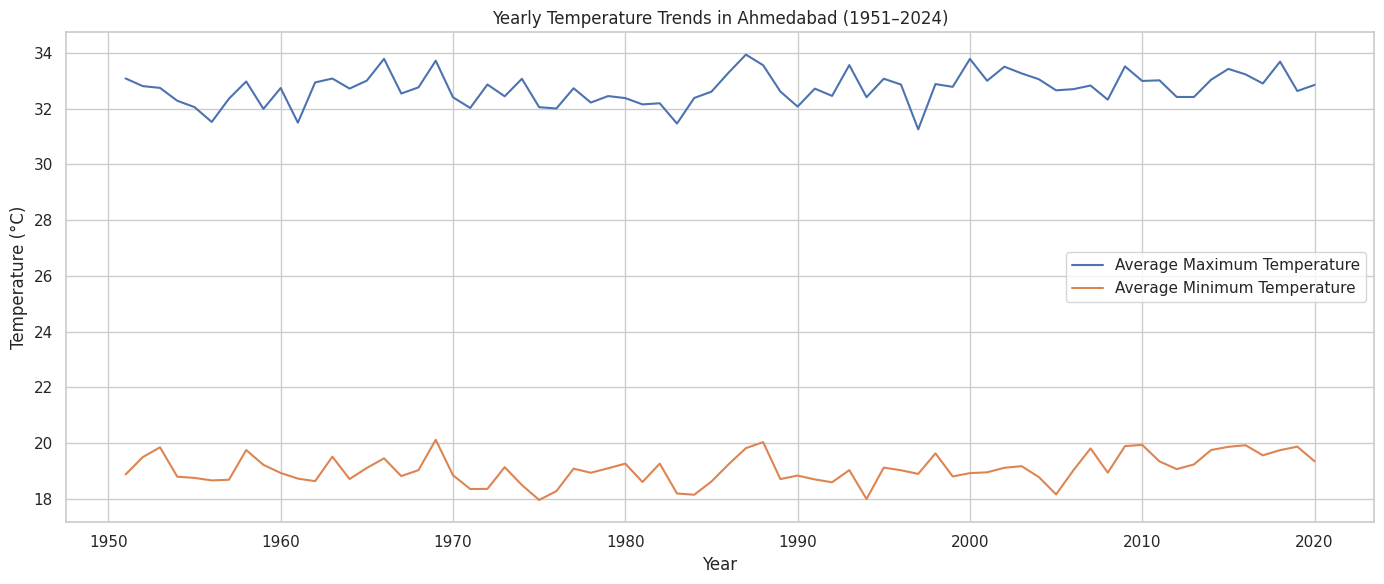

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns

yearly_temp = df_no_missing.groupby("Year")[
    ["Temp Max", "Temp Min"]
].mean()

plt.figure(figsize=(14, 6))

plt.plot(
    yearly_temp.index,
    yearly_temp["Temp Max"],
    label="Average Maximum Temperature"
)

plt.plot(
    yearly_temp.index,
    yearly_temp["Temp Min"],
    label="Average Minimum Temperature"
)

plt.title("Yearly Temperature Trends in Ahmedabad (1951–2024)")
plt.xlabel("Year")
plt.ylabel("Temperature (°C)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

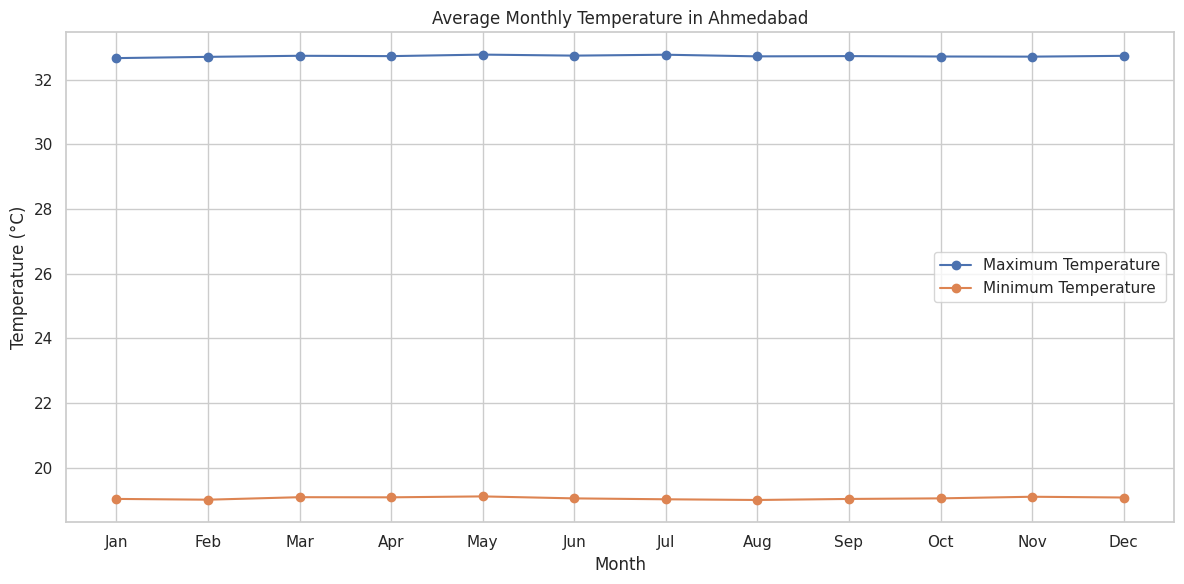

In [18]:
monthly_temp = df_no_missing.groupby("Month")[
    ["Temp Max", "Temp Min"]
].mean()

plt.figure(figsize=(12, 6))

plt.plot(
    monthly_temp.index,
    monthly_temp["Temp Max"],
    marker="o",
    label="Maximum Temperature"
)

plt.plot(
    monthly_temp.index,
    monthly_temp["Temp Min"],
    marker="o",
    label="Minimum Temperature"
)

plt.xticks(
    range(1, 13),
    ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
     "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
)

plt.title("Average Monthly Temperature in Ahmedabad")
plt.xlabel("Month")
plt.ylabel("Temperature (°C)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

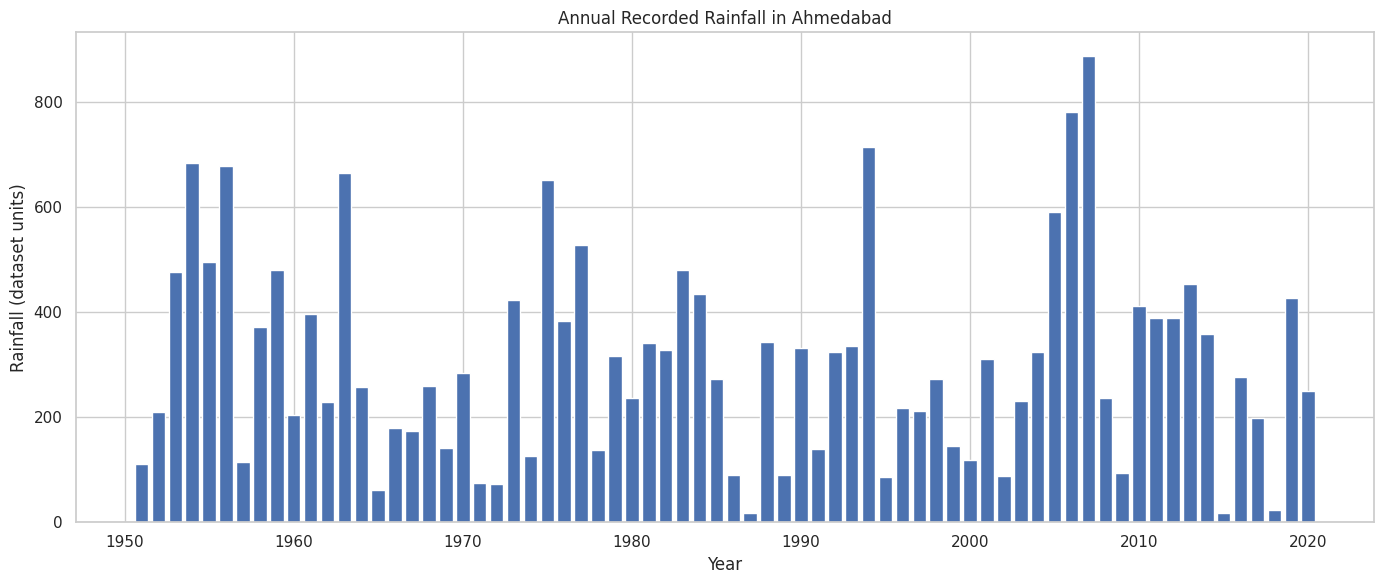

In [19]:
annual_rain = df_no_missing.groupby("Year")["Rain"].sum()

plt.figure(figsize=(14, 6))
plt.bar(annual_rain.index, annual_rain.values)

plt.title("Annual Recorded Rainfall in Ahmedabad")
plt.xlabel("Year")
plt.ylabel("Rainfall (dataset units)")
plt.tight_layout()
plt.show()

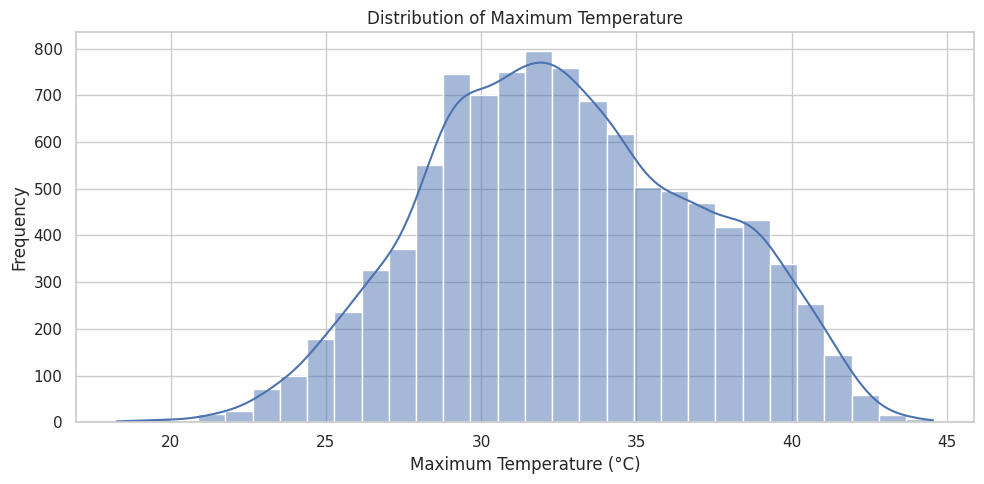

In [20]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df_no_missing,
    x="Temp Max",
    bins=30,
    kde=True
)

plt.title("Distribution of Maximum Temperature")
plt.xlabel("Maximum Temperature (°C)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

In [23]:
hottest = df_no_missing.loc[
    df_no_missing["Temp Max"].idxmax()
]

coldest = df_no_missing.loc[
    df_no_missing["Temp Min"].idxmin()
]

print("Hottest recorded observation:")
print("Date:", hottest["Date"])
print("Maximum temperature:", hottest["Temp Max"], "°C")

print("\nColdest recorded observation:")
print("Date:", coldest["Date"])
print("Minimum temperature:", coldest["Temp Min"], "°C")

Hottest recorded observation:
Date: 1970-12-05 00:00:00
Maximum temperature: 44.56000137 °C

Coldest recorded observation:
Date: 1991-03-01 00:00:00
Minimum temperature: 3.539999962 °C


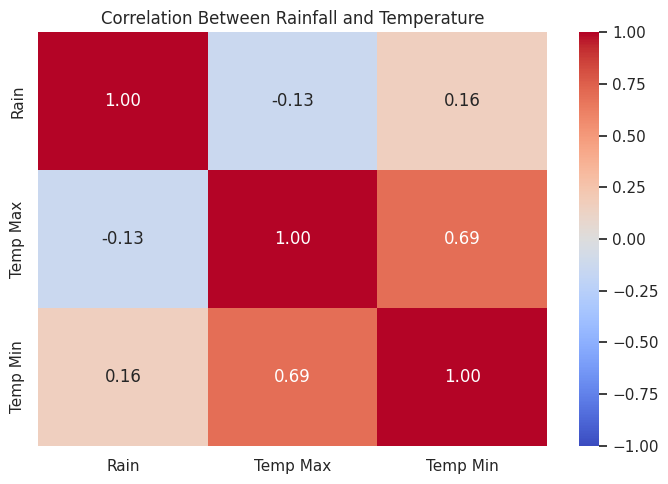

In [24]:
corr = df_no_missing[
    ["Rain", "Temp Max", "Temp Min"]
].corr()

plt.figure(figsize=(7, 5))

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    fmt=".2f"
)

plt.title("Correlation Between Rainfall and Temperature")
plt.tight_layout()
plt.show()